# Figure 1 — task engagement shortens INTs and decouples them from the S-A axis

Rest-vs-task INTs in four datasets: HCP-YA (3T tasks and 7T movies), WAND, HCP-D and Penn LEAD
(session 1). Row A: regional-mean INTs per condition; row B: subject-level INTs across S-A deciles;
bottom row: each subject's coupling of their INT map with the S-A axis, and the formal rest→task
decoupling test.

In [1]:
import copy
import warnings
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import scipy as sp
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline


from src.notebook import (FIG1_AXIS_LABEL, FIG1_DATASET_CONFIGS, FIG1_LABELS, coupling_tests, group_conditions,
                          load_condition_data)
from src.plotting import (draw_coupling_boxes, draw_coupling_scatter, draw_int_rows, figure_scratch_dir,
                          setup_notebook_style)
from snaplab_tools.plotting.utils import save_panel, get_snap_colors
from snaplab_tools.stats import get_fdr_p, significance_stars, steiger_test

setup_notebook_style()

## Configuration and data

In [2]:
fig_dir = figure_scratch_dir()          # spans datasets: no per-dataset subdirectory

In [3]:
my_colors = get_snap_colors(cat_trio=False, as_list=True)

brain_map = 'SA_Axis'

# Labels and per-dataset configs are deep copies of the src.notebook defaults, so edits here change this notebook only, e.g.:
#   DATASET_CONFIGS['HCP-D']['filter'] = None    # the unfiltered HCP-D arm
#   del DATASET_CONFIGS['WAND']                  # leave a dataset out
LABEL_MAP       = copy.deepcopy(FIG1_LABELS)
DATASET_CONFIGS = copy.deepcopy(FIG1_DATASET_CONFIGS)

In [4]:
all_data = {}

# When True, keep only Penn LEAD's session-1 scans, so every figure and test uses one scan per subject.
PENN_SESSION1_ONLY = True

for dataset, cfg in DATASET_CONFIGS.items():
    print(f'\n=== Loading {dataset} ===')
    loaded = load_condition_data(dataset, cfg, penn_session1_only=PENN_SESSION1_ONLY)
    # Regional means, S-A deciles and per-region arrays per condition, in custom_order.
    grouped = group_conditions(loaded['processor'], loaded['data_dict'], loaded['df_neuro'], cfg, brain_map=brain_map)
    all_data[dataset] = {
        **grouped,
        'df_neuro':     loaded['df_neuro'],
        'cfg':          cfg,
        'output_type':  loaded['output_type'],
        # Every condition is tested against the rest column, custom_order's first entry.
        'reference_of': {c: cfg['custom_order'][0] for c in cfg['custom_order'][1:]},
    }
    print(f"  df_ints columns: {grouped['df_ints'].columns.tolist()}")
    print(f"  centiles keys:   {list(grouped['data_dict_centiles'].keys())}")
    print(f"  converted shapes: {[(k, v.shape) for k, v in grouped['data_dict_converted'].items()]}")


=== Loading HCP-YA ===
Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 3912 scans from scan_registry_HCP-YA_multi.csv


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 3912/3912 [00:00<00:00, 7883.62it/s]


Number of subjects: 163
  df_ints columns: ['task-Rest', 'task-Movies', 'task-WM']
  centiles keys:   ['task-Rest', 'task-Movies', 'task-WM']
  converted shapes: [('task-Rest', (163, 400)), ('task-Movies', (163, 400)), ('task-WM', (163, 400))]

=== Loading WAND ===
Loading data for notebooks...
Initialized DataLoader for dataset: WAND
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/WAND
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/WAND/bids
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/WAND/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       178 subjects

	Initialized Timescales for dataset: WAND
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 190 scans from scan_registry_WAND.csv


Loading timescale_auc_zero_crossing: 100%|██████████| 190/190 [00:00<00:00, 7920.31it/s]

Number of subjects: 95
  df_ints columns: ['rest', 'reversallearning']
  centiles keys:   ['rest', 'reversallearning']
  converted shapes: [('rest', (95, 400)), ('reversallearning', (95, 400))]

=== Loading HCP-D ===
Loading data for notebooks...


Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       652 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7677.45it/s]
Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 8502.04it/s]
Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8179.83it/s]


Number of subjects: 552
  df_ints columns: ['task-REST_3T', 'tfMRIEMOTIONPA', 'tfMRICARITPA', 'tfMRIGUESSINGPA']
  centiles keys:   ['task-REST_3T', 'tfMRIEMOTIONPA', 'tfMRICARITPA', 'tfMRIGUESSINGPA']
  converted shapes: [('task-REST_3T', (552, 400)), ('tfMRIEMOTIONPA', (552, 400)), ('tfMRICARITPA', (552, 400)), ('tfMRIGUESSINGPA', (552, 400))]

=== Loading Penn_LEAD ===
Loading data for notebooks...
Initialized DataLoader for dataset: Penn_LEAD
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/Penn_LEAD
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/Penn_LEAD/bids
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/Penn_LEAD/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       132 subjects

	Initialized Timescales for dataset: Penn_LEAD
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031

Loading timescale_auc_zero_crossing_resids: 100%|██████████| 368/368 [00:00<00:00, 8267.96it/s]

Number of subjects: 115
  Penn LEAD: session 1 only -> 198 scans, 99 subjects
  df_ints columns: ['rest', 'nback']
  centiles keys:   ['rest', 'nback']
  converted shapes: [('rest', (99, 400)), ('nback', (99, 400))]


## Figure 1 — top block

Regional-mean INTs (row A) and subject-level INTs across S-A deciles (row B), one column per dataset. Defines `draw_fig1_rows`; the figure is drawn in the **Figure 1** cell below.

In [5]:
dataset_order = list(all_data.keys())
col_widths    = [len(all_data[d]['df_ints'].columns) for d in dataset_order]

def draw_fig1_rows(fig, gs):
    """Figure 1's two rows -- regional-mean violins (A) and subject-level S-A centiles (B),
    one column per dataset -- drawn into `gs`, a 2 x len(dataset_order) grid. Called by the
    Figure 1 cell below. Row A's brackets are paired t-tests of each condition against rest."""
    for col_idx, dataset in enumerate(dataset_order):
        d = all_data[dataset]
        draw_int_rows(
            fig.add_subplot(gs[0, col_idx]), fig.add_subplot(gs[1, col_idx]),
            d['df_ints'], d['data_dict_centiles'], d['reference_of'], d['df_neuro'][brain_map], LABEL_MAP,
            d['cfg']['title'],
            ylabels=(tuple(FIG1_AXIS_LABEL.format(k) for k in ('mean', 'subjects'))
                     if col_idx == 0 else None),
            winsorize_columns=('reversallearning',) if dataset == 'WAND' else ())

### Export: row A's INT maps

The group-mean (across subjects) regional INT map behind each row-A violin, written to `timescales_analysis_fig1_int_maps.csv` beside the figure panels

In [6]:
# Row A's group-mean INT maps, every dataset x condition, as one regions x maps table for use outside this
# notebook. Read straight from df_ints, so the values are exactly the ones row A plots (no winsorizing:
# that is row B only). Columns are '<dataset>_<condition>', in figure order; SA_Axis is kept for reference.
sa_axis = all_data[dataset_order[0]]['df_neuro'][brain_map]
df_int_maps = pd.DataFrame({brain_map: sa_axis.to_numpy()}, index=pd.RangeIndex(len(sa_axis), name='region'))
for dataset in dataset_order:
    d = all_data[dataset]
    assert np.array_equal(d['df_neuro'][brain_map].to_numpy(), sa_axis.to_numpy()), f'{dataset}: parcel order differs'
    for cond in d['df_ints'].columns:
        label = LABEL_MAP.get(cond, cond).replace('\n', '').replace(' ', '')
        df_int_maps[f'{dataset}_{label}'] = d['df_ints'][cond].to_numpy()

int_maps_path = f'{fig_dir}/timescales_analysis_fig1_int_maps.csv'
df_int_maps.to_csv(int_maps_path)
print(f'{df_int_maps.shape[1] - 1} maps x {len(df_int_maps)} regions -> {int_maps_path}')
df_int_maps.head()

11 maps x 400 regions -> /mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/timescales_analysis_fig1_int_maps.csv


,SA_Axis,HCP-YA_Rest,HCP-YA_Movies,HCP-YA_WorkingMemory,WAND_Rest,WAND_ReversalLearning,HCP-D_Rest,HCP-D_Emotion,HCP-D_Carit,HCP-D_Guessing,Penn_LEAD_Rest,Penn_LEAD_WorkingMemory
region,,,,,,,,,,,,
0,186.0,1.332588,1.852216,0.520546,3.132841,3.014392,4.471305,3.935070,3.656682,3.399255,3.143660,2.963460
1,208.0,2.081066,2.040543,0.491335,3.180924,3.136109,4.559023,3.863126,3.855079,3.479781,3.138655,2.819053
2,106.0,1.874330,2.276797,0.819514,3.217839,3.105475,4.572390,3.974110,3.729923,3.510040,3.196155,2.924180
3,78.0,1.738502,2.283736,0.609320,3.262111,3.063762,4.430010,3.897352,3.745593,3.378145,3.164746,2.832174
4,51.0,2.394639,2.515681,0.972631,3.362907,3.184595,4.492401,4.054134,3.845744,3.486211,3.178016,2.884210


## Rest→task decoupling of INTs from the S-A axis

In [7]:
# Each subject's S-A coupling is computed once and reused by the bottom row and by the decoupling test
# (Fisher-z, paired t-test of each condition against rest).
coupling_by_ds, decoupling_rows = {}, []
for dataset, d in all_data.items():
    coupling_by_ds[dataset], _rows = coupling_tests(d['data_dict_converted'], d['reference_of'],
                                                    d['df_neuro'][brain_map].to_numpy(), method='spearman')
    decoupling_rows += [{'dataset': d['cfg']['title'], 'condition': LABEL_MAP.get(r['condition'], r['condition']),
                         **{k: r[k] for k in ('n', 'rho_rest', 'rho_condition', 't', 'p')}} for r in _rows]

df_decoupling = pd.DataFrame(
    decoupling_rows,
    columns=['dataset', 'condition', 'n', 'rho_rest', 'rho_condition', 't', 'p'],
)
# Benjamini-Hochberg FDR across all valid dataset x condition comparisons.
df_decoupling['p_fdr'] = np.nan
valid = df_decoupling['p'].notna()
df_decoupling.loc[valid, 'p_fdr'] = get_fdr_p(df_decoupling.loc[valid, 'p'].to_numpy())
# Significance stars (***/**/*/ns) on the FDR-corrected p-values.
df_decoupling['sig'] = df_decoupling['p_fdr'].apply(significance_stars)

print('Per-subject S-A coupling method: spearman')
with pd.option_context('display.float_format', lambda v: f'{v:.3g}'):
    print(df_decoupling.to_string(index=False))

Per-subject S-A coupling method: spearman
  dataset          condition   n  rho_rest  rho_condition    t        p    p_fdr sig
   HCP-YA             Movies 163     0.274         0.0762 18.4 8.46e-42 5.92e-41 ***
   HCP-YA    Working\nMemory 163     0.274          0.131 12.5 8.58e-26    3e-25 ***
     WAND Reversal\nLearning  95      0.12         0.0824 2.46  0.00778   0.0109   *
    HCP-D            Emotion 552     0.135         0.0504 10.3 3.01e-23 5.28e-23 ***
    HCP-D              Carit 552     0.135           0.12 1.76   0.0391   0.0456   *
    HCP-D           Guessing 552     0.135          0.045 10.7 1.55e-24 3.63e-24 ***
Penn LEAD    Working\nMemory  99    0.0824         0.0483 1.66     0.05     0.05   *


## Figure 1 — bottom row

Per-subject S-A coupling by dataset (left) and HCP-YA rest vs movie / task coupling across subjects (right). Defines `draw_extra_figure`; the figure is drawn in the **Figure 1** cell below.

In [8]:
# The HCP-YA per-subject couplings behind the bottom row's scatter panels, reused from the decoupling cell.
hcpya = all_data['HCP-YA']
df_corr = pd.DataFrame(
    {cond: coupling_by_ds['HCP-YA'][cond] for cond in hcpya['cfg']['custom_order']},
    index=hcpya['subject_ids'],
)
df_corr.index.name = 'subject_ids'
df_corr.head()

,task-Rest,task-Movies,task-WM
subject_ids,,,
100610,0.423428,0.157536,0.229001
102311,0.265419,0.096463,0.136235
102816,0.190492,-0.210297,0.106796
104416,0.082540,-0.106474,-0.059729
105923,0.243838,0.210248,0.062208


In [9]:
# All three bottom-row panels and the decoupling test share one set of per-subject couplings.
sig_lookup = {(r.dataset, r.condition): r.sig for r in df_decoupling.itertuples()}

# Panels B/C use 'task-Tasks' when all 3T tasks are collapsed (average_3t_tasks) and 'task-WM' otherwise.
hcpya_cfg  = all_data['HCP-YA']['cfg']
task_col   = 'task-Tasks' if hcpya_cfg['average_3t_tasks'] else 'task-WM'
task_label = 'Tasks' if hcpya_cfg['average_3t_tasks'] else 'Working Memory'

def draw_extra_figure(fig, gs):
    """The extra figure's three panels -- A: per-subject S-A coupling by dataset; B/C: HCP-YA
    rest vs movies / task coupling across subjects -- drawn into `gs`, a 1 x 3 grid. Called by
    the Figure 1 cell below."""
    axA = fig.add_subplot(gs[0, 0])
    axB = fig.add_subplot(gs[0, 1])
    axC = fig.add_subplot(gs[0, 2])
    draw_coupling_boxes(axA, [dict(title=d['cfg']['title'], columns=d['cfg']['custom_order'],
                                   reference_of=d['reference_of'], coupling=coupling_by_ds[ds])
                              for ds, d in all_data.items()],
                        sig_lookup, LABEL_MAP, my_colors[:2], ('Rest', 'Movie/Task'))
    # Panels B & C: HCP-YA per-subject coupling, Rest vs Movies / Rest vs Tasks (or WM)
    draw_coupling_scatter(axB, df_corr['task-Rest'], df_corr['task-Movies'], 'Rest', 'Movies', my_colors[:2], 'HCP-YA')
    draw_coupling_scatter(axC, df_corr['task-Rest'], df_corr[task_col], 'Rest', task_label, my_colors[:2], 'HCP-YA')

In [10]:
# Steiger's test for dependent correlations: does the cross-subject Rest-Movies coupling correlation (panel B, Pearson) differ from Rest-Tasks (panel C)?
steiger_cols = ['task-Rest', 'task-Movies', task_col]
dfc = df_corr[steiger_cols].dropna()

r_xy = sp.stats.pearsonr(dfc['task-Rest'],   dfc['task-Movies']).statistic   # panel B: Rest vs Movies
r_xz = sp.stats.pearsonr(dfc['task-Rest'],   dfc[task_col]).statistic        # panel C: Rest vs Tasks/WM
r_yz = sp.stats.pearsonr(dfc['task-Movies'], dfc[task_col]).statistic        # shared off-diagonal

z, p = steiger_test(r_xy, r_xz, r_yz, n=len(dfc), alternative='two-sided')

print(f'n = {len(dfc)} subjects')
print(f'r(Rest, Movies) = {r_xy:.3f}   [panel B]')
print(f'r(Rest, {task_label})  = {r_xz:.3f}   [panel C]')
print(f'r(Movies, {task_label}) = {r_yz:.3f}  [shared]')
print(f"Steiger's test (two-sided): z = {z:.3f}, p = {p:.3g}  {significance_stars(p)}")

n = 163 subjects
r(Rest, Movies) = 0.461   [panel B]
r(Rest, Working Memory)  = 0.125   [panel C]
r(Movies, Working Memory) = 0.334  [shared]
Steiger's test (two-sided): z = 3.971, p = 7.16e-05  ***


## Figure 1

Both blocks drawn as one figure and written as one panel, `timescales_analysis_fig1_combined`.

                   n  dof  mean_diff          t              p         p_corr  \
condition                                                                       
Movies           400  399  -0.240334 -11.921920   3.080138e-28   3.080138e-28   
Working\nMemory  400  399  -1.569154 -61.420953  1.853500e-205  3.706999e-205   

                 sig  
condition             
Movies           ***  
Working\nMemory  ***  
                      n  dof  mean_diff          t              p  \
condition                                                           
Reversal\nLearning  400  399  -0.198742 -35.861572  6.986214e-127   

                           p_corr  sig  
condition                               
Reversal\nLearning  6.986214e-127  ***  
             n  dof  mean_diff           t    p  p_corr  sig
condition                                                   
Emotion    400  399  -0.683808 -131.537933  0.0     0.0  ***
Carit      400  399  -0.740241 -154.322953  0.0     0.0  ***
Guessing

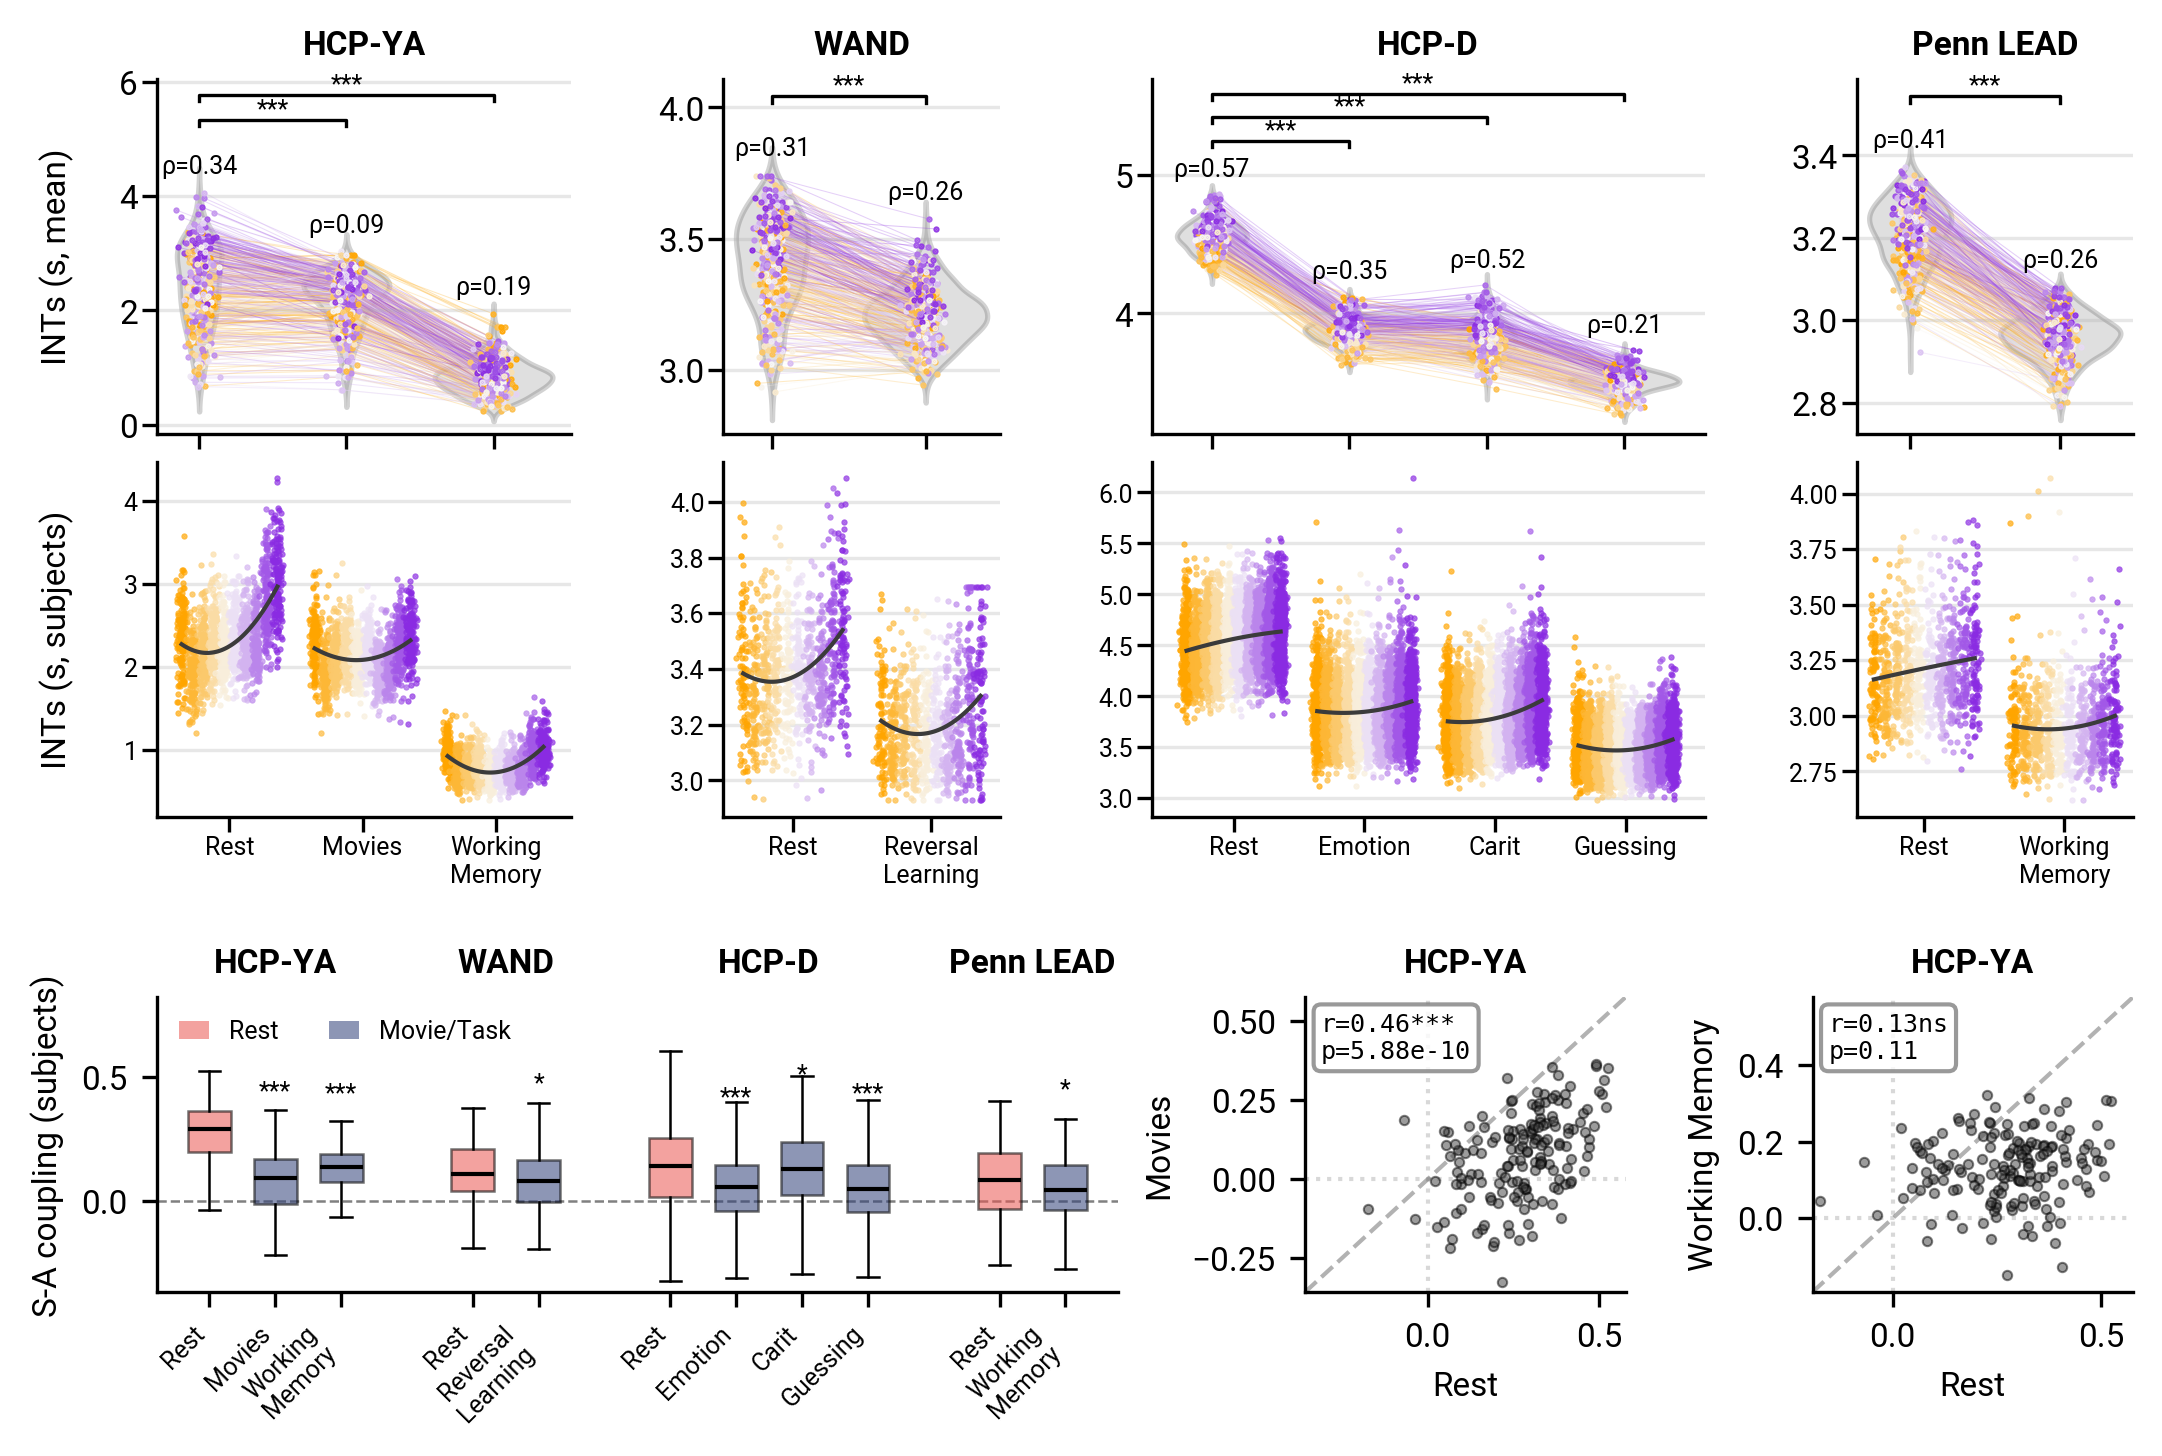

In [11]:
# The two INT rows on top and the coupling panels below, spaced by EXTRA_HEIGHT and BLOCK_GAP.
EXTRA_HEIGHT = 1.5    # inches given to the bottom row
BLOCK_GAP    = 0.35   # vertical gap between the two blocks, as a fraction of the mean block height

fig = plt.figure(figsize=(8.5, 3.75 + EXTRA_HEIGHT), dpi=300)
outer = gridspec.GridSpec(2, 1, height_ratios=[3.75, EXTRA_HEIGHT], hspace=BLOCK_GAP)
draw_fig1_rows(fig, gridspec.GridSpecFromSubplotSpec(
    2, len(dataset_order), subplot_spec=outer[0],
    width_ratios=col_widths, hspace=0.08, wspace=0.4,
))
draw_extra_figure(fig, gridspec.GridSpecFromSubplotSpec(
    1, 3, subplot_spec=outer[1], width_ratios=[3, 1, 1], wspace=0.35,
))

plt.tight_layout()
save_panel(fig, fig_dir, 'timescales_analysis_fig1_combined', transparent=True)
plt.show()